# ALTogether 최종 판정 가이드라인

**셀 실행이나 모델 다운로드 없이 읽을 수 있습니다.**

이 문서는 Train에서 사례별 피드백을 누적한 뒤, 반복 비교 실험과 인간 검토를 거쳐 선정한 가이드라인 3개의 전문입니다. 이진판정, 후보 탐색, 최종 선택 순서로 제시합니다. 각 **원문** 셀의 내용은 실제 사용하는 MD 파일과 같습니다.

공식 라벨링 가이드라인 v1.1과 함께 사용하는 보조 판단 기준입니다. Train에서 문서를 만들고 보완하며, 실제 사용 단계인 Frozen에서는 선택한 버전을 고정합니다. 각 단계의 피드백 에이전트는 원본 입력·최초 판정·공식 기준·해당 MD를 대조해 재검토 필요성을 결정합니다.

| 단계 | Train에서 문서를 갱신하는 사례 | Frozen에서 사용하는 방법 |
|---|---|---|
| 이진판정 | 최초 적절·부적절 판단이 실제 이진 정답과 다른 경우 | 통과 또는 피드백을 선택하고, 피드백이 있는 경우 재판정 |
| 후보 탐색 | 실제 오류 유형이 후보에 없는 경우 | 필요한 후보를 추가하도록 선택적 피드백 |
| 최종 선택 | 정답이 후보 안에 있는데 잘못 선택한 경우 | 필요할 때 고정 후보 안에서 다시 선택 |

규칙으로 확정된 사례는 정해진 우회 경로를 따릅니다. 위 표는 각 단계의 일반적인 문서 학습·적용 조건입니다. 정답을 이용하는 Train의 재판정 성능과 정답 없이 수행하는 Frozen 성능은 구분합니다.

원본 버전: `20261105_080500_5cf95c` 실행에 보존된 최종 문서. 이 사본은 진행 중인 추가 실험의 문서로 교체하지 않았습니다.

- [1. 이진판정](#binary)
- [2. 후보 탐색](#candidates)
- [3. 최종 선택](#final)
- [학습·추론 실행 Notebook](01_ALTogether_학습과추론.ipynb)
- [공식 라벨링 가이드라인 v1.1](../data/docs/라벨링-가이드라인-v1.1.md)


## 가이드라인을 만드는 단계와 사용하는 단계

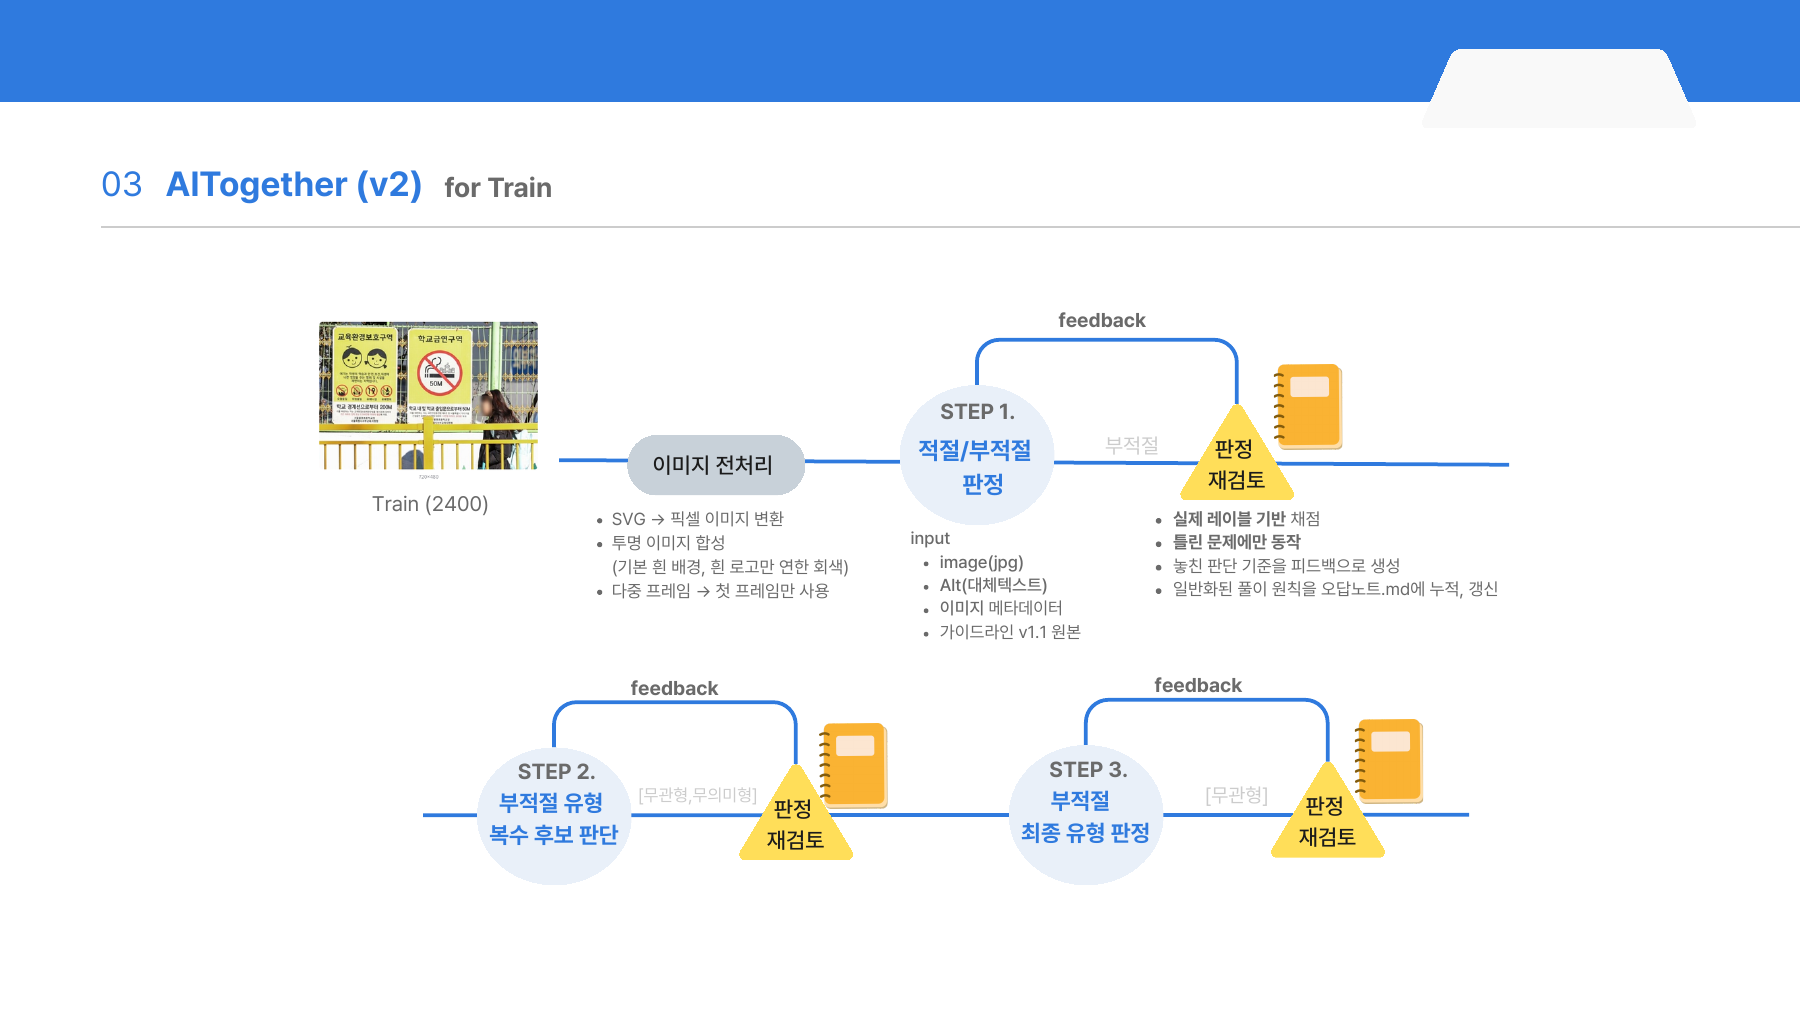

*발표자료 10쪽. 아래의 세 가이드라인은 각 단계의 피드백을 누적한 뒤, 반복 비교 실험과 인간 검토를 거쳐 선정한 문서다.*


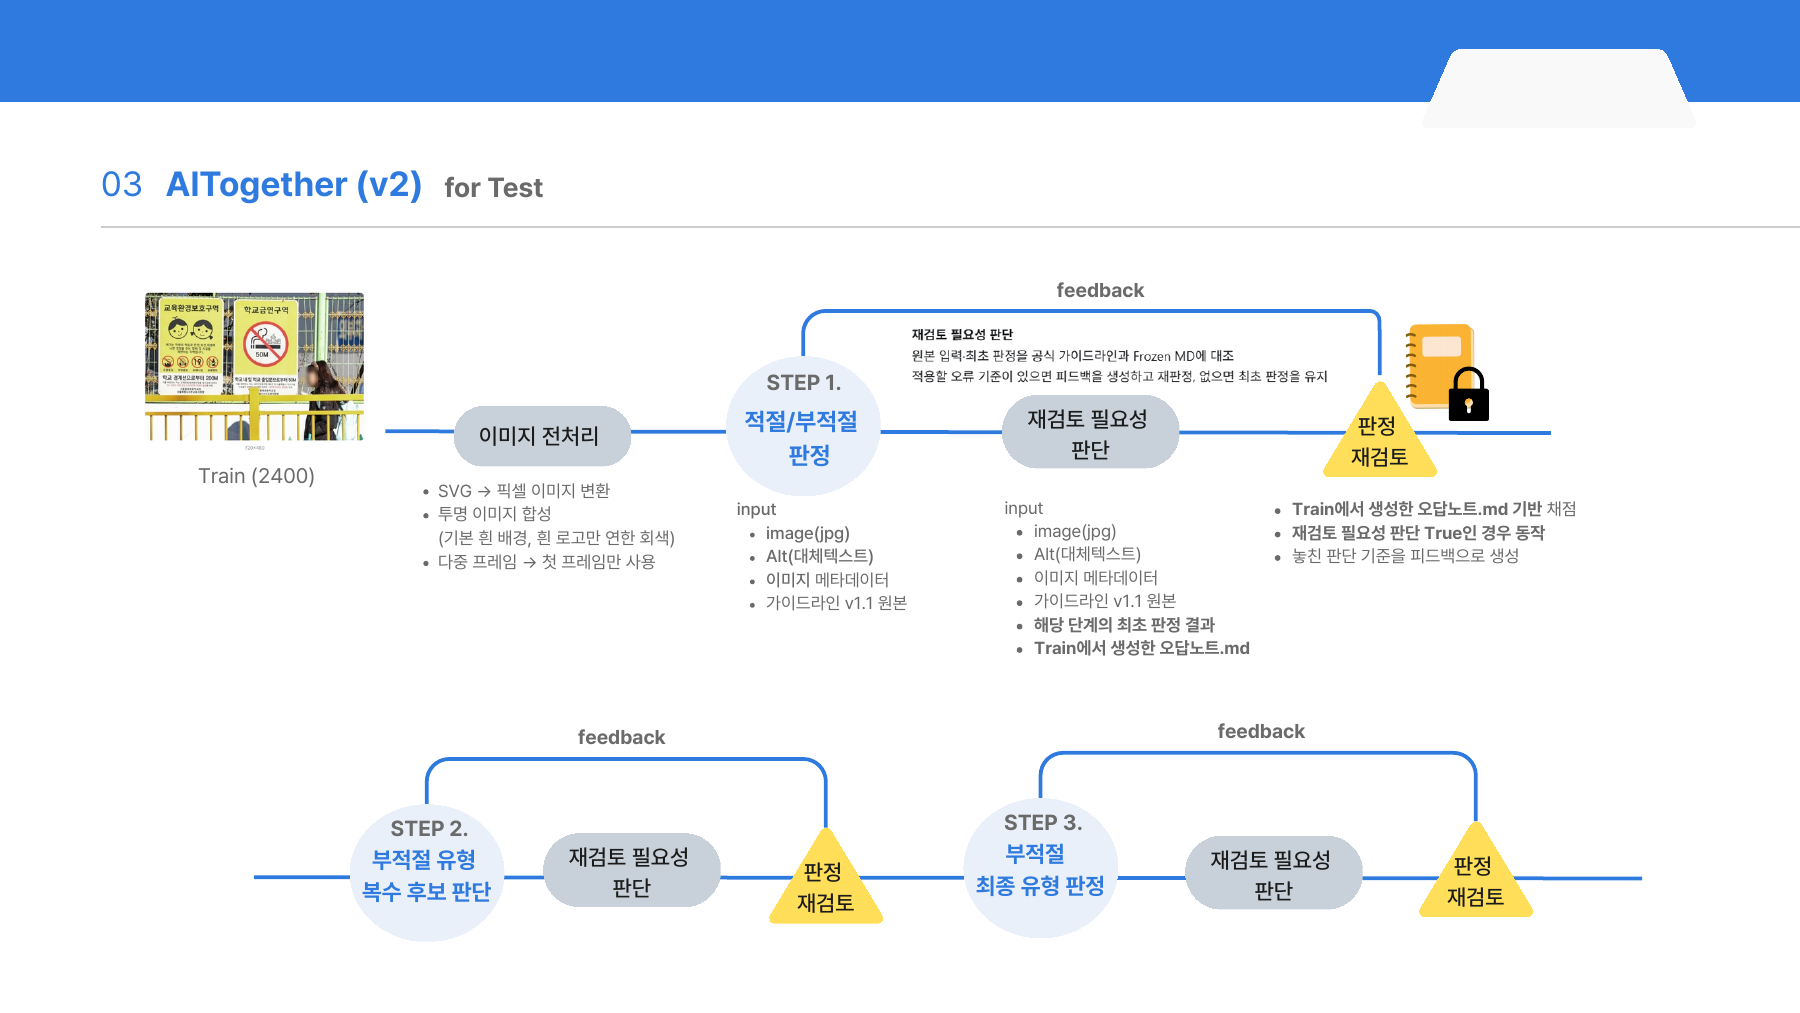

*발표자료 11쪽. 그림의 Train(2,400)은 발표 당시 학습 자료를 정답 없이 다시 평가한 입력이다. 실제 사용에서는 같은 Frozen 절차에 Test 600건을 넣는다. ‘MD 기반 채점’은 정답과의 점수 계산이 아니라 가이드라인에 따른 재검토를 뜻한다.*


<a id="binary"></a>

## 1. 적절·부적절 판단

이미지의 핵심 정보와 기능이 alt 및 문맥에서 전달되는지 확인한다. 일반 사진, 링크 이미지, 텍스트 포함 이미지 등의 경계를 다룬다.

원본: [reflection_guidelines.md](../model/guidelines/reflection_guidelines.md)  
문서 SHA-256: `ced3550f8b2e1702b6d12dc78e240657ba7bdc1a579138ff3b1962898beffabd`

### 원문


# Reflection 판단 가이드라인

## 누적 재검토 체크리스트

### 근거의 역할을 구분한다

- `alt_text`, 실제 인접 본문인 `context_text`, 사람이 읽는 같은 링크 문구인 `link_dest`만 이미지 정보를 직접 대신 전달할 수 있다.
- `page_title`, `heading_path`, URL·경로는 참고 자료일 뿐이며, 여기에 대상명이 있다는 사실만으로 이미지에만 있는 텍스트·기능·상태의 누락을 보완하지 않는다.
- 이미지 내 포함된 텍스트 정보가 `alt_text`, `context_text`, `link_dest` 중 어디에서 어떻게 전달되고 있는지 항목별로 대응시켜 확인한다.

### 이미지 역할별로 확인한다

- **일반 촬영 사진 및 썸네일**: `alt_text`가 사진의 구체 대상·행동·상태 중 현재 역할에 필요한 핵심을 식별하는지 확인한다. 시설명·공간명·인물명·행사명처럼 구체 대상을 이미 식별하면, 장면을 더 자세히 묘사할 수 있다는 이유만으로 부적절로 바꾸지 않는다. 특히 관광지·시설 소개 카드에서 실제 피사체의 고유 장소명이 있고 뒤에 `img`·`이미지`·`사진`만 붙었다면 접미사를 제외한 장소명이 사진 대상을 식별하는지 먼저 본다. 반면 비교 결과·처리 상태·특정 행동이 사진의 핵심인데 대상명만 있다면 누락을 다시 확인한다.
- **복원·복제·처리 전후·디지털화 결과**: `원본`, `복제본`, `처리 전/후`, `N페이지 처리 결과 사진` 같은 역할·순서 표시와 인접 문맥을 함께 보고 실제 대상·변화·처리 단계가 식별되는지 확인한다. `N페이지_`와 같은 위치 표지나 `img`·`이미지`·`사진` 접미사 하나만을 누락 근거로 삼지 않는다. 접두를 뺀 문구가 자연어로 처리 대상과 상태를 설명하고 인접 본문이 기록물의 정체와 처리 내역을 제공하면, 페이지 번호나 밑줄만으로 파일명형·불충분형을 확정하지 않는다. 핵심 대상이나 상태가 실제로 빠졌을 때만 부적절 가능성을 재검토한다.
- **빈 alt의 비링크 사진**: 페이지 제목이나 주제 문구가 있다는 사실만으로 장식성을 인정하지 않는다. 풍경·역사 자료·전시물·현장 사진처럼 제거할 때 고유한 시각 정보가 사라지면 부적절이며, 순수 장식 또는 인접 본문과 완전히 중복되는 경우에만 적절로 본다.
- **편집 사진·영상 썸네일 및 텍스트 포함 그래픽**: 이미지 내 실질 정보(제목, 설명, 고유명, 주체, 지역, 대상, 기간, 장소, 방법, 수치, 제한, 문의, 행동 문구, 유형/분류 등 구체적 식별 정보) 중 `alt_text`에서 누락된 핵심 내용이 있는지 대조한다.
    - 인접 본문(`context_text`)이나 링크 문구(`link_dest`)가 이미지의 상태를 설명하고 있더라도, 이미지 내에만 존재하는 구체적인 식별 정보나 핵심 내용이 `alt_text`에서 누락되었는지 다시 확인한다.
    - 빈 alt 썸네일에서 자격·기한·제한·경고·필수 행동 등 진입 전 필수 정보가 이미지에만 있다면 누락으로 본다.
    - 간행물 표지·포스터·배너에서 제목과 핵심 목적이 식별되면 부제·발행기관·홍보 문구·작은 연락처·디자인 요소의 누락만으로는 판정을 뒤집지 않는다. 기간·장소·대상·수치도 현재 이미지의 목적에서 사용자가 반드시 알아야 하는 핵심인지, 실제 인접 문맥이 대신하는지를 확인한 후 누락으로 본다.
- **화면 캡처·지도·도표·절차도**: 인접 문장이 주제나 단계명만 언급하는지, 화면의 조작 대상·선택 상태·공간 관계·수치까지 동등하게 설명하는지 구분한다.
- **QR·기능성 이미지**: `GO`·`바로가기` 같은 일반 동작, 단순 URL, 원시 경로 나열은 목적지 설명이 아니다. alt 또는 링크 문구에 구체적인 서비스·콘텐츠의 목적지나 동작 대상이 명시되어 있는지 확인한다.
    - 이미지가 링크의 유일한 콘텐츠인지, 아니면 인접한 `link_dest`나 `context_text`가 목적지와 내용을 충분히 설명하여 이미지는 보조적 식별 정보만 제공하는 역할인지 구분하여 `alt_text`의 정보 제공 수준이 적절한지 다시 확인한다.
    - 비밀번호 표시/숨김 등 특정 동작 아이콘의 경우, alt가 대상 지칭을 넘어 구체적인 동작이나 상태를 설명하는지 확인한다.
- **로고·아이콘**: 단순 묘사 부족만으로 적절 판정을 뒤집지 않는다. 정보성 아이콘인지, 제거해도 무방한 장식성 이미지인지 구분한다. 링크 밖 아이콘이 조항 성격 등을 나타내는 정보성 이미지라면, alt가 인접 텍스트와 동일하더라도 식별 역할을 수행하므로 적절로 본다.
    - 게시물 목록의 첨부 여부·파일 형식 아이콘이나 콘텐츠 부재 플레이스홀더처럼 이미지의 전부가 상태 표시에 해당하면, `첨부파일 아이콘`·`이미지 파일`·`이미지없음`은 그 역할·상태를 직접 전달한다. `아이콘`·`이미지`라는 유형어가 포함됐다는 이유만으로 무의미형을 적용하지 않고, 실제 그림이 더하는 정보가 파일 존재·형식·부재 상태뿐인지 확인한다.
- **중복**: 같은 링크 내에서 링크 문구와 alt가 동일 정보를 반복하여 추가 정보가 없을 때 적용한다. 특히 장식성 이미지임에도 alt가 링크 텍스트를 그대로 반복하여 중복 낭독을 유발하는지 확인한다. 캡션이 있어도 이미지의 종류·역할을 식별하는 alt는 적절할 수 있다.

### 재판정 변경 기준

- 최초 부적절 판정을 적절로 바꾸려면, 최초 판정이 지적한 누락·왜곡이 실제로 없거나 누락으로 지적한 내용이 현재 역할에서 필수 정보가 아니어야 한다. 같은 정보가 `alt_text`, 실제 인접 본문, 사람이 읽는 링크 문구에 명시된 경우도 포함한다. 단순히 “문맥이 충분하다”는 추정이나 “더 자세히 쓸 수 있다”는 품질 개선 제안만으로 결론을 바꾸지 않는다.


<a id="candidates"></a>

## 2. 오류 유형 후보 탐색

부적절로 판정된 사례에서 가능한 오류 유형을 놓치지 않기 위한 기준이다. 재검토는 후보를 넓히는 목적으로 사용하며, 기존 후보와 추가 후보를 합친다.

원본: [type_reflection_guidelines.md](../model/guidelines/type_reflection_guidelines.md)  
문서 SHA-256: `a77ee2c2c438dce16fde8b1e96a8cdf4548abd7033d500bdea95a97fe42e95f4`

### 원문


# 오류 유형 후보 Reflection 가이드라인

## 누적 재검토 체크리스트

- 이미지가 링크 내부 또는 외부에 있더라도, alt 텍스트가 동일 링크 내의 텍스트나 인접 캡션·본문 등 주변 텍스트와 중복되어 정보 이득이 0이고 스크린리더에 의해 반복 낭독되는 구조인지 확인하여 '중복형' 판정 누락을 방지한다. 특히 이미지가 링크의 유일한 콘텐츠가 아님에도 alt가 동일 링크 내 텍스트를 반복하는 경우를 주의 깊게 검토한다. 반면, 이미지가 링크의 유일한 콘텐츠라면 중복 낭독이 없으므로 중복형이 아니며, 목적지 설명 여부에 따라 '불충분형' 등을 검토한다. 또한 alt가 목적지를 구체적으로 설명하지 못하고 단순 동작이나 명칭만 반복한다면, 중복형이 아니라 핵심 정보가 누락된 '불충분형'에 해당하는지 다시 확인한다.
- 썸네일 이미지의 경우, 단순 그래픽(아이콘·로고 등)은 링크 텍스트와 중복 시 '중복형'으로 보나, 촬영 사진은 사진 자체의 시각적 내용(누가, 무엇을, 어떤 장면인지)을 설명해야 한다. 따라서 alt가 링크 텍스트를 반복하여 사진 자체의 시각적 내용을 설명하지 못했다면, 중복형이 아닌 '불충분형'에 해당하는지 다시 확인한다.
- 텍스트를 포함한 정보성 이미지(그래픽)인 경우, 이미지가 단순 현장 사진인지 아니면 실질적 정보를 담은 '텍스트 포함 이미지'인지 역할을 먼저 판정한다. 이후 이미지 내의 실질적인 핵심 정보(기간, 일시, 장소, 대상, 수치, URL, QR코드 목적지 등)가 alt나 인접 텍스트 어디에도 없어 정보 이득이 없는 상태인지 확인하여 '불충분형' 판정 누락을 방지한다. 특히 alt가 링크 텍스트를 반복하여 정보 이득이 0인 '중복형'인지, 아니면 이미지 내의 실질적 핵심 정보가 누락되어 '불충분형'에 해당하는지 엄격히 구분한다. 이때 alt가 이미지 내 일부 텍스트를 옮겼더라도, 누락된 다른 실질적 정보가 존재하여 핵심 정보를 충분히 전달하지 못한다면 '불충분형'으로 판정한다. 또한 alt가 파일명 형태를 띠고 있더라도 이미지 내 핵심 정보의 누락 여부를 우선적으로 검토한다.
- alt 텍스트가 파일명, 경로, 시스템 파라미터, 속성값의 형태를 띠고 있더라도, 실제 내용이 이미지의 유형만 단순하게 지칭하거나 아무런 의미가 없는 상투어(예: "이미지", "사진", "배너")인지 확인하여 '무의미형' 해당 여부를 다시 고려한다.
- 이미지 속 구체적인 대상이나 포함된 텍스트가 alt 텍스트와 서로 일치하지 않아 정보가 왜곡되었는지 확인한다. 이때, 단순히 목적지 설명이 부족한 '불충분형'보다 우선순위가 높은 '무관형'의 정의를 충족하는지 검토하여 판정 누락을 방지한다.
- 후보 단계는 정답 가능성을 넓게 보존하는 단계다. 이미지 제거 후 고유 정보·목적지·동작·상태가 사라지지 않고 비어 있지 않은 alt가 붙었다면, 다른 유형 후보가 함께 있더라도 **'장식오용형' 후보를 제외하지 않는다.**
- 링크 안 아이콘뿐 아니라 링크 밖의 로고·기관 상징·국기·마스코트·단순 인물 일러스트·별·화살표·경고 그림·섹션 제목이나 정책 슬로건을 꾸미는 분위기용 사진도 장식성일 수 있다. 특히 해당 이미지가 기능성 아이콘이 아닌 단순 장식성 이미지이거나 정보 전달 목적이 없는 단순 분위기 조성용 사진일 가능성이 있는지, 그리고 이 경우 내용성 alt가 부여된 것이 장식오용형 정의를 충족하는지 다시 확인한다. alt가 보이는 대상이나 기관명을 정확히 적었거나 주변 문맥이 충분하더라도, 이미지 자체가 정보나 기능을 더하지 않으면 내용성 alt가 붙은 장식오용형 후보를 포함한다.
- 반대로 기사·기록 사진처럼 고유 장면이 본문 이해에 필요하거나, 로고가 기관 식별의 유일한 수단이거나, 아이콘이 상태·파일 형식·새 창 열림 등 텍스트에 없는 정보를 더하면 장식오용형 후보를 기계적으로 넣지 않는다.
- 후보 단계에서는 비기능성 촬영 사진도 주변 제목·장소명·정책 문구가 이미지의 역할과 목적을 이미 모두 전달하고, alt가 그 문구에 `이미지`·`사진`만 붙여 반복하며 사진의 고유 장면이 과업에 필요하지 않다면 **장식오용형 후보를 반드시 함께 보존한다.** 관광지·시설·정책 슬로건 사진이라는 이유만으로 정보성으로 확정하여 장식오용형을 제외하지 않는다. 이 단계에서는 중복형·불충분형과 장식오용형을 함께 남기고 최종 선택에 맡긴다.
- 같은 링크나 캡션의 문구를 alt가 그대로 반복하는 구조는 '중복형' 후보를 반드시 포함한다. 이미지도 장식일 가능성이 있으면 후보 단계에서는 '중복형'과 '장식오용형'을 함께 남기고 최종 단계에서 구체적 경계 규칙으로 선택한다.

<a id="final"></a>

## 3. 최종 오류 유형 선택

확정된 후보 집합 안에서 이미지·alt·문맥과 후보별 근거를 비교해 한 유형을 선택하기 위한 기준이다.

원본: [final_reflection_guidelines.md](../model/guidelines/final_reflection_guidelines.md)  
문서 SHA-256: `e818dabcd7fa9d2a26e1f272874c9d3ed0f3ed3fb9858d610ca2c3fead7fc831`

### 원문


# 최종 오류 유형 선택 Reflection 가이드라인

## 누적 재검토 체크리스트

- **이미지 역할 및 장식성 우선 판정**: alt 문자열을 분석하기 전, 이미지가 제거되어도 정보 손실이 없는 '순수 장식성'인지 먼저 판정한다. 특히 아이콘이나 촬영 사진의 경우, 클릭 가능한 기능성 버튼/정보 전달 목적의 사진인지 아니면 단순히 페이지 분위기를 조성하거나 입력 필드를 보조하는 단순 장식성 이미지인지 역할을 명확히 구분한다. 순수 장식 이미지에 내용성 alt가 부여된 경우 다른 우선순위보다 **'장식오용형'** 여부를 최우선적으로 확인한다.
- **텍스트 및 시각적 요소의 정보 성격과 누락 여부 구분**: 이미지의 성격(단순 그래픽 vs 실질적 정보 포함)을 구분하여 '중복형', '불충분형', '무의미형'의 경계를 판정한다.
    - **실질적 정보가 포함된 이미지 (촬영 사진, 정보성 배너/그래픽-VR 360 포함, 포스터, 표지, 지도, 도면, 화면 캡처, 단계별 복원 과정 및 상세 설명 등)**: 링크/인접 텍스트로 대체될 수 없는 핵심 정보(기간·일시·대상·자격요건·수치·장소·문의처, 구체적 행동 지침, 시각적 묘사, 이미지 내 텍스트 등)의 포함 여부를 확인한다.
        - **촬영 사진 썸네일**: alt가 링크/인접 텍스트를 반복하여 정보 이득이 0이라 하더라도, 사진 자체의 시각적 묘사가 누락되었다면 중복형이 아닌 **'불충분형'**으로 판정한다. 특히 alt에 "사진", "이미지" 등 유형을 언급하는 상투어나 파일 관리 흔적(파일명형 특성)이 포함되어 있더라도, 시각적 묘사나 핵심 정보가 누락되었다면 '무의미형'이나 '파일명형'보다 **'불충분형'**을 최우선으로 적용한다.
        - **정보성 배너/그래픽 (포스터, 표지, VR 360 등)**: 이미지 내 텍스트나 특수 정보 중 링크 텍스트에 없는 실질적 정보가 존재함에도 alt가 링크 텍스트를 반복하거나 상투적 표현만 담고 있다면, 정보 이득이 0인 중복형이 아니라 **'불충분형'**을 우선 선택한다. 특히 alt가 이미지 내의 모든 실질 정보(제목, 기간, 대상, 자격 요건 등)를 빠짐없이 담고 있는지 확인하여, 일부 핵심 정보라도 누락되었다면 **'불충분형'**으로 판정한다. 핵심 정보 누락이 지배적인 경우, 일부 정보의 불일치(무관형 특성)보다 정보 누락 특성을 우선하여 확인한다.
        - **상투어/유형 언급**: alt가 "이미지", "사진", "리플릿", "관련사진" 등 이미지의 유형만 언급하더라도, 이미지 내 실질적 정보나 구체적인 장면 묘사 대상이 존재하거나 링크의 목적지를 구체적으로 설명하지 못했다면 '무의미형'보다 **'불충분형'**을 우선 적용한다.
    - **단순 그래픽 구성 요소/슬로건 위주 이미지 (로고, 아이콘 등)**: 디자인적 구성, 로고, 슬로건, 단순 제목만 포함하여 alt가 링크 텍스트를 반복함으로써 추가 정보 이득이 없는 경우 **'중복형'**으로 판정한다. 이때 상투어가 섞여 있더라도 정보 이득이 0이라면 '무의미형'보다 **'중복형'**을 우선 고려한다.
- **링크 및 CTA(Call to Action) 요소의 목적지 설명 확인**: 
    - **이미지가 링크의 유일한 콘텐츠인 경우**: alt가 단순 동작(예: "GO", "더보기")만 설명하거나, '이미지'와 같은 상투어를 포함하여 이미지 유형을 언급하더라도 구체적인 목적지 설명이 누락되었다면 '무의미형'보다 **'불충분형'**을 우선 적용한다.
    - **인접 텍스트가 목적지를 충분히 설명하는 경우**: 이미지가 추가 정보를 제공하지 않는 그래픽이라면, 링크 텍스트가 이미 목적지를 알려주고 있으므로 '불충분형'이 아닌 **'중복형'** 또는 **'장식오용형'** 가능성을 검토한다.
- **중복형, 무관형, 불충분형, 무의미형의 경계 확인**: 
    - alt의 추가 표현이 단순히 링크 텍스트를 반복하는 수준이면 **'중복형'**이다.
    - 목적지를 나타내는 로고/아이콘의 alt가 시각적 묘사는 없으나 목적지 정보와 일치한다면 '무관형'이 아닌 **'중복형'**이다.
    - **'불충분형' vs '무관형'**: 이미지 내 핵심 정보의 누락이 지배적인지, 아니면 alt에 포함된 외부 정보로 인한 내용 불일치가 더 결정적인지 비교하여 판정한다. 단순 번역 수준의 alt라도 이미지 내 핵심 정보가 누락되었다면 '무관형'보다 **'불충분형'**을 우선 확인한다.
    - **'무관형' vs '무의미형'**: alt가 이미지 내용과 전혀 일치하지 않는 엉뚱한 정보일 때만 **'무관형'**을 선택한다. 반면, 이미지의 유형을 언급하는 상투어와 파일 관리 흔적(파일명형 특성)이 섞여 실질적 정보가 없는 경우라면 **'무의미형'** 또는 **'파일명형'** 가능성을 먼저 검토한다.
- **파일명형과 타 유형의 경계 확인**: 
    - 확장자가 없더라도 버전 정보, 편집 접미사, 경로 표시, 파일 시스템식 밑줄 연결 등 관리 흔적이 주를 이룬다면 **'파일명형'**으로 판정한다. 단, 이미지 내에 단계별 복원 과정이나 상세 설명 등 핵심 정보가 포함되어 있음에도 alt가 파일 관리 흔적으로만 구성되어 정보 누락이 심각한 경우에는 '파일명형'보다 **'불충분형'**을 우선하여 확인한다.
    - 내용 없이 상투적인 용어나 기호만 나열된 경우에만 **'무의미형'**을 선택한다.

## 사람이 검토하고 운영에 반영하는 방법

1. 문제가 된 이미지·alt·메타데이터와 판정 근거를 대시보드에서 확인합니다.
2. 어느 단계의 기준이 부족했는지 구분하고, 공식 기준과 충돌하거나 한 사례에만 맞는 표현이 없는지 검토합니다.
3. 원본 MD의 **사본**을 수정해 새 Frozen 실행에서 비교합니다. 오답 교정뿐 아니라 기존 정답의 악화와 유형별 성능도 확인합니다.
4. 검토한 버전을 운영에 적용하고 이전 문서는 보존합니다.

이 Notebook은 제출 시점 문서의 열람용 사본입니다. 실제 추론은 `model/guidelines/`의 MD를 읽습니다. Notebook만 수정해도 추론 기준이 바뀌는 것은 아닙니다. 반복 비교와 인간 검토를 수행했으며 정식 K-fold 교차검증을 의미하지 않습니다.
